# Transformer Optimization - Activities Guide

- *Original author: Maya Hage-Hassan*
- *Adapted by Théodore Cherrière*

## Overview

This guide walks through the seven MATLAB scripts in MainScripts/, progressing from model validation to full Pareto front comparison. Each script builds on the previous one, introducing new optimization concepts.

**The problem:** Design a shell-type single-phase transformer (230V/24V, 50Hz, 8A) that minimizes both **energy losses** and **total mass** simultaneously, subject to thermal, electrical, and geometric constraints.

**Design variables (7):**

| Variable     | Description                       | Unit    | Typical Range     |
| ------------ | --------------------------------- | ------- | ----------------- |
| $a$        | Lateral core leg width            | $m$   | 3--30 $mm$      |
| $b$        | Winding window height             | $m$   | 14--95 $mm$     |
| $c$        | Winding window width              | $m$   | 6--40 $mm$      |
| $d$        | Core leg thickness                | $m$   | 10--80 $mm$     |
| $n_1$      | Primary turns                     | -       | 200--1200         |
| $S_{1fil}$ | Primary conductor cross-section   | $m^2$ | 0.15--19 $mm^2$ |
| $S_{2fil}$ | Secondary conductor cross-section | $m^2$ | 0.15--19 $mm^2$ |

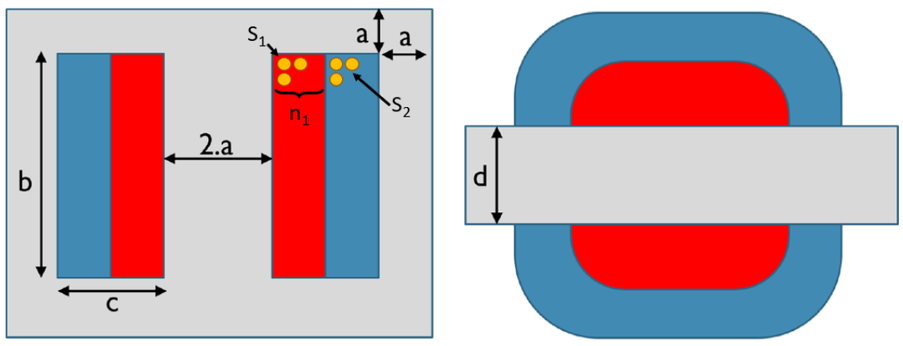

**Objectives (2):**

1. **Minimize Losses** (1-efficiency)
2. **Minimize Mass**

**Constraints (6):**

- Copper temp $\leq$ 120°C
- Iron temp $\leq$ 100°C
- Voltage drop $\leq$ 10%
- Magnetizing current $\leq$ 10%
- Fill factors $\leq$ 0.6
- Physical model convergence.

Some articles are available in `Bibliography`.

---

## A) Validate the Physics Model 

- Go to file `MainScripts/A_LaunchModel.m`.

**What it does:** Runs the transformer physics simulator (ConceptionModel.m) with a test design and displays results.

**What to do?**

1. Identify the design variables, parameters, outputs.
2. Fix the nonlinear system resolution in `Model/ConceptionModel.m` by writing a proper Newton method.
3. Add a linesearch in `Model/ConceptionModelLineSearch.m`

**What to observe?**

- Convergence rate for different reference inputs `xTest_0`, `xTest_1`, ..., `xTest_4`
- The output vector is: `[M_tot; Tcuivre; Tfer; DV2/V2; I10/I1; ren; f1; f2; Pj; Pfer ; crit]`

---

## B) Single-Objective Optimization

- Go to file `MainScripts/B_LaunchOptimisation.m`.

**What it does:** Uses MATLAB's `fmincon` with the SQP algorithm to optimize a SINGLE objective (either losses OR mass). This finds extremal points of the Pareto front.

**What to do?**

1. Define the objective function `myfun` either as the losses or the mass.
2. Define the constraint function `mycon`.
3. Run the optimization, for optimizing either the mass or the losses.
4. Play with the initial point and algorithm parameters.

**What to observe?**

- Note the minimal and maximal values of the mass and losses.
- Is the optimized result always the same?

---

## C) Multistart Single-Objective

- Go to file `MainScripts/C_LaunchOptimisationMultiStart.m`.

**What it does:** Runs `fmincon` from different random starting points, keeping the best converged result. This mitigates the risk of getting stuck in a local minimum.

**What to do?**

1. Setup and run the multistart loop.
2. If the Parallel Computing Toolbox is available, parallelise the code using `parfor`.
3. Play with algorithm parameters, especially constraints tolerance.
4. Analyse the results.

**What to observe?**

- Proportion of "good" vs "bad" optimization results with respect to the algorithm paramters.
- Determine a good number of starting point: we want a good result at the end, without compromising the performance to much.

---

## D) Weighted Sum (linear) Scalarization

- Go to file `MainScripts/D_LaunchOptimisationPonderation.m`.

**What it does:** Traces the Pareto front by optimizing a weighted combination of both objectives. By sweeping the weight parameter omega from 0 to 1, we obtain different point from the Pareto front.

**What to do?**

1. Determine the objective function and constraints.
2. Run the algorithm and trace the Pareto front. Play with the algorithm parameters.
3. Can linear scalarization work for nonconvex Pareto front? Why?
4. Propose and implement stategies to minimize the computation time.

**What to observe?**

- Comment on the Pareto fronts obtained with and without normalization.

---

## E) Epsilon-Constraint Method

- Go to file `MainScripts/E_LaunchOptimisationEpsConstr.m`.

**What it does:** Traces the Pareto front by minimizing losses subject to a mass or loss constraint, which is swept.

**What to do?**

1. Determine the objective function and constraints.
2. Run the algorithm and trace the Pareto front. Play with the algorithm parameters.
3. Can epsilon-constraint work for nonconvex Pareto front? Why?
4. Propose and implement stategies to minimize the computation time.

**What to observe?**

- Comment on the Pareto fronts obtained with different constraints bounds.

---

## F) NSGA-II Evolutionary Algorithm

- Go to file `MainScripts/F_LaunchNSGAII.m`.

**What it does:** Runs a custom implementation of NSGA-II (Non-dominated Sorting Genetic Algorithm II) from Kalyanmoy Deb et al. NSGA-II is a population-based evolutionary algorithm that directly computes the Pareto front without scalarization.

**Key concepts:**

- **Population-based:** Maintains many candidate solutions simultaneously (vs. single-point methods).
- **Non-dominated sorting:** Ranks solutions by their Pareto front number (front 1 = Pareto-optimal).
- **Crowding distance:** Maintains diversity within each front to spread solutions evenly.
- **Elitism:** Better solutions from both parent and child generations survive to the next generation.
- **SBX Crossover:** Simulates biological crossover with a distribution parameter `etaX`.
- **Polynomial Mutation:** Adds small random perturbations with probability `pM`.

```mermaid

flowchart TD
    A("Generate initial population<br/>Size N = nmbOfIndivs")
    B["Evaluate fitness<br/>Fct: ObjContr(x)<br/>Output: ObjVals 2xN, ConstrVals 7xN"]
    C["Non-dominated sorting<br/>NSGA_Rank<br/>Output: Ranking, NmbOfFront"]

    A --> B --> C

    subgraph G["Generate offspring population - NSGA_ChildGen"]
        direction TB
        D["Selection<br/>NSGA_Tournament<br/>Pars: 250x2 parent indices"]
        E["Crossover<br/>NSGA_SBX<br/>pX, etaX <br/>Simulated Binary Crossover"]
        F["Mutation<br/>NSGA_Mutate(XIndivs)<br/>pM, etaM<br/>Polynomial mutation"]
        D --> E --> F
    end

    C --> D

    H["Evaluate offspring fitness<br/>ChildObjVals, ChildConstrVals"]
    I["Combine parent and offspring populations<br/>Par_ChildGen = [ParGen ChildGen]<br/>Population size = 2N = 1000"]

    F --> H --> I

    subgraph J["Elitist environmental selection"]
        direction TB
        K["NSGA_Rank on 2N population<br/>Non-dominated sorting<br/>Crowding distance"]
        L["Select N best individuals<br/>Front ascending, crowding descending<br/>ParGen = top N individuals"]
        K --> L
    end

    I --> K

    M{"Stopping criterion<br/>i >= nmbOfGens?"}

    L --> M
    M -->|No - next generation| D
    M -->|Yes - done| N["Return final Pareto front<br/>ParGen: 7x500<br/>ObjVals: 2x500<br/>NmbOfFront: 500x1"]

    style G stroke:#e000ff,stroke-width:2px
    style J stroke:#e000ff,stroke-width:2px
    style K fill:#e8f0ff,stroke:#2455cc,stroke-width:2px
    style N fill:#e8f5e9,stroke:#2e7d32,stroke-width:2px
    style A fill:#e8f0fe,stroke:#4285f4,stroke-width:2px
    style E fill:#fef7e0,stroke:#f9ab00,stroke-width:2px
    style F fill:#fce8e6,stroke:#ea4335,stroke-width:2px
```

**Parameters to experiment with:**

| Parameter              | Default | Effect of increasing                       |
| ---------------------- | ------- | ------------------------------------------ |
|                        |         |                                            |
| `mbOfIndivs`         | 500     | More diversity, slower                     |
|                        |         |                                            |
| `mbOfGens`           | 100     | More convergence, slower                   |
| `etaX` (crossover)   | 0.5     | Children closer to parents (exploitation)  |
| `etaM` (mutation)    | 0.5     | Mutations closer to parents (exploitation) |
| `pM` (mutation rate) | 0.1     | More exploration, potential disruption     |

**What to do?**

1. Explain the steps of NSGA-II algorithm.
2. From the ressource in `Bibliography`, give and explain 3 different quality indicators of a numerical Pareto front.
3. Play with the parameters.
4. Compare with MATLAB builtin `gamultiobj`.

**What to observe?**

- Pareto front quality according to some indicators.
- Computation time.

---

## G) Comprehensive Method Comparison

- Go to file `MainScripts/G_Comparison.m`.

**What it does:** Nothing is pre-implemented, it's your time to play!

**What to do?**

1. Compare different multi-objective optimization algorithms (random search, linear scalarization, epsilon-constraint, genetic algorithm, )
2. Try to implement best method in terms of Pareto front quality and computation time.
3. Save the results and plot the comparison.

**What to observe?**

- Quality of Pareto front.
- Computation time.